# F7 · Search on skin and on all eight sections

* **Needs:** `R7_queries.ipynb` (results/queries/).
* **Writes:** `figures/fig7_skin/panels/{A,B,C,DE}.{pdf,png}` and `figures/fig7_skin/fig7_skin.{pdf,png}`.

Panels:
* **A:** gene-list search on skin. The three skin signatures; cells coloured by signature score; Spindle-naive's 10
  nearest tiles outlined.
* **B:** whole-tile search on skin. A held-out epidermis tile (rule in `queries.py`) and Spindle-naive's top 10, on the
  section and up close; the class compositions; every skin held-out query against a random 10.
* **C:** every section. Composition difference of the held-out tiles to Spindle-naive's top 10, Spindle's first 10
  and a random 10 (mean ± s.d. over seeds 0–4).
* **D, E:** every tissue signature on every section. Cliff's δ of the signature score (D) and co-variation lift on S
  (E) of the 10 tiles of Spindle-naive and of Spindle.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import style as ps

FIG = "fig7_skin"
RES = ps.ROOT / "results" / "queries"
EX = RES / "skin_example"
SIG = [("Melanocyte_Tumor", "Melanocyte"), ("Keratinocyte_Epidermis", "Keratinocyte"),
       ("Immune_Infiltrate", "Immune")]
CLASS_COLORS = ["#882255", "#EE7733", "#33BBEE", "#DDDDDD"]  # melanocyte, keratinocyte, immune, other
NAIVE, SPINDLE, SPINDLE_PARTIAL = (ps.TIER_COLORS["naive"], ps.TIER_COLORS["spindle"],
                                   ps.TIER_COLORS["spindle_partial"])
KEYS = ps.DATASET_ORDER
XLAB = [ps.DATASET_LABELS[k] for k in KEYS]


def at(fig, x, y, w, h, **kw):
    """Axes w x h mm at (x, y) mm from the panel's top-left corner."""
    W, H = ps.size_mm(fig)
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H], **kw)


def text(fig, x, y, s, size=ps.LABEL_PT, ha="left", **kw):
    W, H = ps.size_mm(fig)
    fig.text(x / W, 1 - y / H, s, fontsize=size, ha=ha, va="top", **kw)


def legend(fig, cx, cy, handles, ncol, **kw):
    W, H = ps.size_mm(fig)
    fig.legend(handles=handles, ncol=ncol, loc="center", bbox_to_anchor=(cx / W, 1 - cy / H), **kw)


def hbar(fig, x, y, w, cmap, vmin, vmax, ticks):
    ax = at(fig, x, y, w, 2.5)
    cb = fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap), cax=ax, orientation="horizontal", ticks=ticks)
    cb.outline.set_linewidth(0.5)
    return cb


def spatial(ax, x0, x1, y0, y1):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")


def extent(xy, w):
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    return x0, x1, y0, y1, w * (y1 - y0) / (x1 - x0)


def dataset_axis(ax):
    ax.set_xticks(range(len(KEYS)))
    ax.set_xticklabels(XLAB, rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.6, len(KEYS) - 0.4)

## A · Gene-list search on skin

figures/fig7_skin/panels/A.pdf/.png: 180 x 45 mm, 1.3 / 2.0 MB


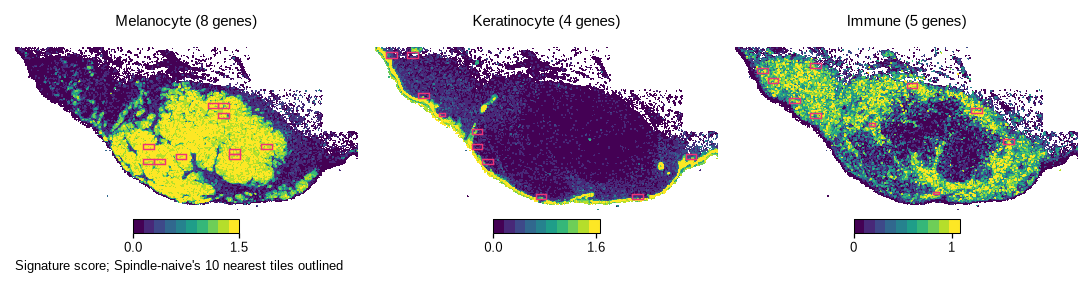

In [2]:
SIG_W, A_W, A_H = 58.0, 180.0, 45.0


def panel_a(fig):
    z = np.load(EX / "signature_cells.npz")
    xy = z["xy"]
    x0, x1, y0, y1, h = extent(xy, SIG_W)
    cmap = ListedColormap(colormaps["viridis"](np.linspace(0, 1, 10)))  # 10 steps keep the PNG within budget
    L = pd.read_csv(RES / "lists.csv")
    n_genes = L[(L.key == "skin_melanoma") & (L.method == "naive_partial")].set_index("list").n_genes
    for i, (name, label) in enumerate(SIG):
        x = 61.0 * i
        s = z[f"score_{name}"].astype(np.float32)
        vmax = float(np.quantile(s, 0.995))
        ax = at(fig, x, 6, SIG_W, h)
        o = np.argsort(s, kind="stable")
        ax.scatter(xy[o, 0], xy[o, 1], s=0.12, c=s[o], cmap=cmap, vmin=0, vmax=vmax, lw=0, rasterized=True,
                   antialiased=False)
        for bx0, by0, bx1, by1 in z[f"top_{name}"]:
            ax.add_patch(Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, ec=ps.QUERY_COLOR, lw=0.7))
        spatial(ax, x0, x1, y0, y1)
        text(fig, x + SIG_W / 2, 0.5, f"{label} ({int(n_genes[name])} genes)", ha="center")
        hbar(fig, x + 20, 35, 18, cmap, 0, vmax, [0, np.floor(10 * vmax) / 10])
    text(fig, 0, 42, "Signature score; Spindle-naive's 10 nearest tiles outlined", size=ps.TICK_PT)


fig = ps.panel(A_W, A_H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · Whole-tile search on skin

figures/fig7_skin/panels/B.pdf/.png: 180 x 45 mm, 0.6 / 1.3 MB


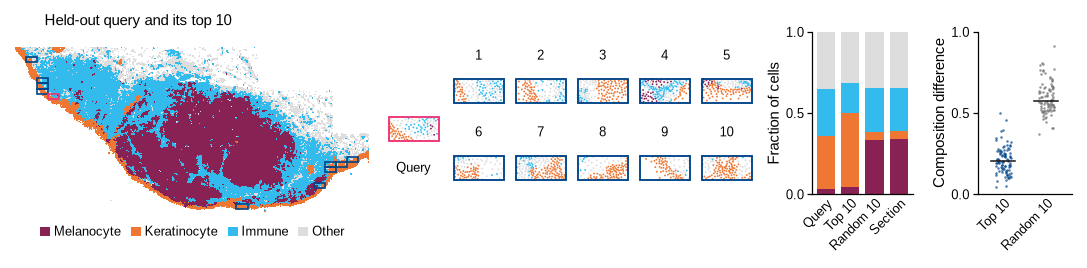

In [3]:
B_W, B_H = 180.0, 45.0
TX, TY, TS = 63.0, 9.0, 10.5  # thumbnails: hit 1 x, first row y, step


def panel_b(fig):
    z = np.load(EX / "example_cells.npz")
    names = [str(n) for n in z["classes"]]
    col = np.array(CLASS_COLORS)
    xy, cls = z["xy"], z["cls"]
    text(fig, 5, 0.5, "Held-out query and its top 10")
    x0, x1, y0, y1, h = extent(xy, 60.0)
    ax = at(fig, 0, 6, 60.0, h)
    o = np.argsort(cls != len(names) - 1, kind="stable")  # "Other" underneath
    ax.scatter(xy[o, 0], xy[o, 1], s=0.12, c=col[cls[o]], lw=0, rasterized=True, antialiased=False)
    for k in range(len(z["tiles"]) - 1, -1, -1):
        bx0, by0, bx1, by1 = z[f"bbox{k}"]
        ax.add_patch(Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, lw=0.8,
                               ec=ps.QUERY_COLOR if k == 0 else NAIVE, zorder=3 if k == 0 else 2))
    spatial(ax, x0, x1, y0, y1)
    legend(fig, 30, 6 + h + 3, [Patch(fc=c, ec="none", label=n) for n, c in zip(names, CLASS_COLORS)], 4,
           handlelength=0.8, columnspacing=0.8, handletextpad=0.3)

    for k in range(len(z["tiles"])):
        if k == 0:
            x, y = TX, TY + 6.5
        else:
            x, y = TX + 11 + TS * ((k - 1) % 5), TY + (0 if k <= 5 else 13)
            text(fig, x + 4.5, y - 2.5, str(k), size=ps.TICK_PT, ha="center")
        bx0, by0, bx1, by1 = z[f"bbox{k}"]
        side = max(bx1 - bx0, by1 - by0) * 1.06
        cx, cy = (bx0 + bx1) / 2, (by0 + by1) / 2
        ax = at(fig, x, y, 9, 9)
        ax.scatter(*z[f"xy{k}"].T, s=0.8, c=col[z[f"cls{k}"]], lw=0, rasterized=True)
        ax.add_patch(Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, lw=0.9,
                               ec=ps.QUERY_COLOR if k == 0 else NAIVE))
        spatial(ax, cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2)
    text(fig, TX + 4.5, TY + 16.5, "Query", size=ps.TICK_PT, ha="center")

    ex = pd.read_csv(EX / "example.csv").set_index("set")
    sets = [("query", "Query"), ("top10", "Top 10"), ("random10", "Random 10"), ("section", "Section")]
    ax = at(fig, 135, 3.5, 17, 27.5)
    for i, (s, _) in enumerate(sets):
        bottom = 0.0
        for n, c in zip(names, CLASS_COLORS):
            v = ex.loc[s, n]
            ax.bar(i, v, 0.75, bottom=bottom, color=c, lw=0)
            bottom += v
    ax.set_xticks(range(len(sets)))
    ax.set_xticklabels([l for _, l in sets], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Fraction of cells")

    q = pd.read_csv(RES / "per_dataset" / "skin_melanoma" / "seed0_tile_queries.csv")
    ax = at(fig, 163, 3.5, 16, 27.5)
    rng = np.random.default_rng(0)
    for i, (c, color) in enumerate((("tv_naive", NAIVE), ("tv_random", ps.MUTED))):
        v = q[c].to_numpy()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=1.5, c=color, lw=0, alpha=0.7, zorder=2)
        ax.plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color=ps.INK, lw=0.75, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Top 10", "Random 10"], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Composition difference")


fig = ps.panel(B_W, B_H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## C · Composition difference on every section

figures/fig7_skin/panels/C.pdf/.png: 60 x 54 mm, 0.0 / 0.3 MB


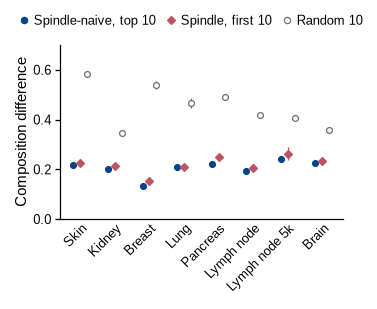

In [4]:
C_W, C_H = 60.0, 54.0


def panel_c(fig):
    T = pd.read_csv(RES / "tiles.csv")
    cols = ["tv_naive", "tv_spindle", "tv_random"]
    m = T.groupby("key")[cols].mean().loc[KEYS]
    s = T.groupby("key")[cols].std().loc[KEYS]
    kinds = [("tv_naive", "Spindle-naive, top 10", NAIVE, "o", -0.2, True),
             ("tv_spindle", "Spindle, first 10", SPINDLE, "D", 0.0, True),
             ("tv_random", "Random 10", ps.MUTED, "o", 0.2, False)]
    ax = at(fig, 9, 9.5, 48, 29.5)
    for c, _, color, mk, dx, filled in kinds:
        x = np.arange(len(KEYS)) + dx
        ax.errorbar(x, m[c], yerr=s[c], fmt=mk, ms=2.8, mfc=color if filled else "white", mec=color, mew=0.6,
                    ecolor=color, elinewidth=0.6, capsize=0, zorder=2)
    dataset_axis(ax)
    ax.set_ylim(0, 0.7)
    ax.set_yticks([0, 0.2, 0.4, 0.6])
    ax.set_ylabel("Composition difference")
    legend(fig, 31, 5.5, [Line2D([], [], ls="", marker=mk, ms=3, mfc=c if f else "white", mec=c, mew=0.6, label=l)
                          for _, l, c, mk, _, f in kinds], 3, handletextpad=0.2, columnspacing=0.6)


fig = ps.panel(C_W, C_H)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## D, E · Every tissue signature on every section
One panel with two axes and their shared legend.

figures/fig7_skin/panels/DE.pdf/.png: 120 x 54 mm, 0.0 / 0.5 MB


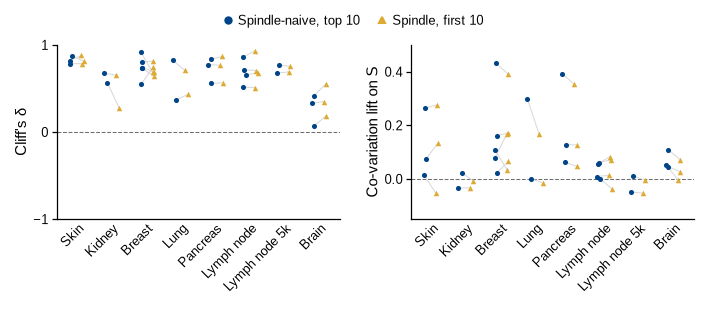

In [5]:
DE_W, DE_H = 120.0, 54.0


def panel_de(fig):
    L = pd.read_csv(RES / "lists.csv")
    t = L[L.method == "naive_partial"].set_index(["key", "list"])
    ts = L[L.method == "spindle_partial"].set_index(["key", "list"]).loc[t.index]
    rng = np.random.default_rng(0)
    xi = np.array([KEYS.index(k) for k, _ in t.index], dtype=float)
    jit = rng.uniform(-0.06, 0.06, len(xi))
    for x0, col, ylab, lim, ticks in ((1, "delta", "Cliff's δ", (-1, 1), [-1, 0, 1]),
                                      (61, "lift", "Co-variation lift on S", (-0.15, 0.5), [0, 0.2, 0.4])):
        ax = at(fig, x0 + 9, 9.5, 48, 29.5)
        ax.axhline(0, color=ps.MUTED, lw=0.5, ls="--", zorder=1)
        a, b = t[col].to_numpy(), ts[col].to_numpy()
        for x, ya, yb in zip(xi + jit, a, b):
            ax.plot([x - 0.17, x + 0.17], [ya, yb], color=ps.LIGHT, lw=0.5, zorder=1)
        ax.scatter(xi + jit - 0.17, a, s=6, marker="o", c=NAIVE, lw=0, zorder=2)
        ax.scatter(xi + jit + 0.17, b, s=7, marker="^", c=SPINDLE_PARTIAL, lw=0, zorder=2)
        dataset_axis(ax)
        ax.set_ylim(*lim)
        ax.set_yticks(ticks)
        ax.set_ylabel(ylab)
    legend(fig, 60, 5.5, [Line2D([], [], ls="", marker="o", ms=3, color=NAIVE, label="Spindle-naive, top 10"),
                          Line2D([], [], ls="", marker="^", ms=3, color=SPINDLE_PARTIAL, label="Spindle, first 10")],
           2, handletextpad=0.2, columnspacing=1.2)


fig = ps.panel(DE_W, DE_H)
panel_de(fig)
ps.save_panel(fig, FIG, "DE")

## Full figure

figures/fig7_skin/fig7_skin.pdf/.png: 180 x 146 mm, 1.9 / 4.1 MB


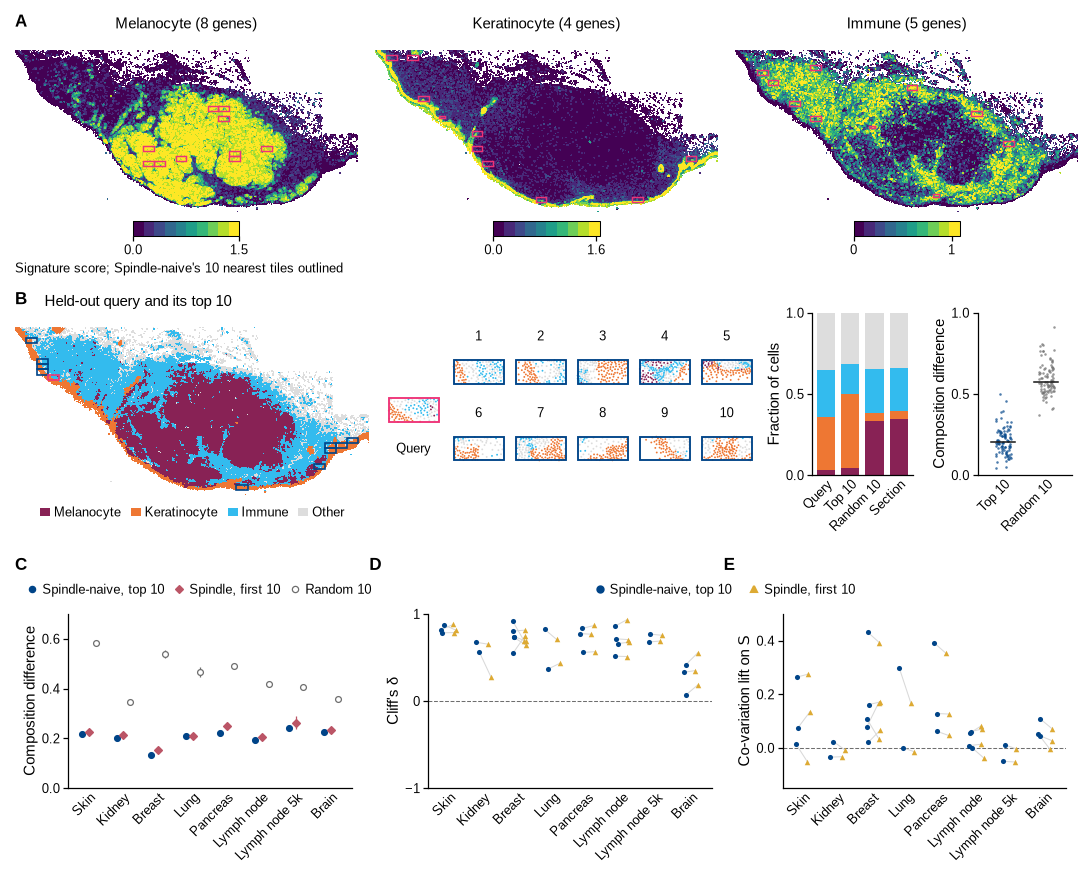

In [6]:
page = ps.page(180, 146)
panel_a(ps.place(page, "A", 0, 0, A_W, A_H))
panel_b(ps.place(page, "B", 0, 47, B_W, B_H))
panel_c(ps.place(page, "C", 0, 92, C_W, C_H))
panel_de(ps.place(page, "D", 60, 92, DE_W, DE_H))
page.text(120 / 180, 1 - 92 / 146, "E", fontsize=ps.LETTER_PT, fontweight="bold", ha="left", va="top")
ps.save_figure(page, FIG)